In [ ]:
# Preserve the original working directory after moving this notebook into figures/.
from pathlib import Path as _NotebookPath
import os as _notebook_os
_notebook_directory = _NotebookPath.cwd()
if _notebook_directory.name == "figures" and (_notebook_directory.parent / "ec_estimation").is_dir():
    _notebook_os.chdir(_notebook_directory.parent)


# Differential cross covariance e SSI — DCM vs MOU, 62 regioni corticali

Analisi corticale **a partire dal prodotto**: `D_DCM = A[:62,:62] @ Q0[:62,:62]`; `D_MOU = J[:62,:62].T @ Q0[:62,:62]`. Quindi `S=(D-D.T)/2` e `SSI=S.sum(axis=0)`. Non si calcola D su 74 regioni per poi tagliare S. Diagonali mantenute; nessun valore assoluto o soglia.

Q0 replica Figure 5: filtro Butterworth ordine 2, 0.01–0.1 Hz, TR BOLD 0.72 s; correlazione dei 100 segnali corticali originali, poi media dei blocchi secondo `clust_idx_LEMON`. È una FC ridotta, non una covarianza neurale latente DCM. DCM usa A come salvata; MOU viene trasposta.

**Abbinamento MOU provvisorio:** i file MOU non hanno ID. L'ordine viene ricostruito come nei notebook originali (ID ordinati, entrambi i run BOLD con 1200 volumi), ma non è una prova dell'ordine di salvataggio. Confronti MOU–DCM da interpretare condizionatamente a questa assunzione. Le DCM e le FC sono abbinate per ID esplicito.

Prima sezione: DCM RESULTS_YA, RUN1/RUN2. Seconda: DCM `codici/results/*TR1_realData_var11_emo_points16.mat`, confrontata con MOU e Q0 RUN1 della **stessa coorte**. La variante points23 non viene mescolata con points16. `TR1` è il nome della serie; il filtro dei dati HCP mantiene TR=0.72 s.

In [100]:
from pathlib import Path
from collections import Counter
import re
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy import signal
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits

PROJECT=Path('/home/benedetta/Scripts/Insight_project')
BOLD=Path('/home/benedetta/hcp_parcellated')
DCM_ROOT=Path('/readonly/insights/RESULTS_YA_new_1000')
TR1_ROOT=Path('/home/benedetta/codici/results')
OUT=PROJECT/'numpy files/SSI_cortical_DCM_MOU'
FIGURES=PROJECT/'Figures/SSI_cortical_DCM_MOU'
OUT.mkdir(parents=True,exist_ok=True); FIGURES.mkdir(parents=True,exist_ok=True)
threadpool_limits(limits=4)
N_ROIS=62
mapping=loadmat(PROJECT/'clust_idx_LEMON.mat')['clust_idx_LEMON'].ravel()[:100].astype(int)
assert np.array_equal(np.unique(mapping),np.arange(1,63))
W=(mapping[:,None]==np.arange(1,63)).astype(float); W/=W.sum(axis=0)
b,a=signal.butter(2,[.01,.1],btype='bandpass',fs=1/.72)
font=PROJECT/'Notebook figure/Avenir-Oblique.ttf'
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family']=font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams['font.size']=12

def bold_path(sid,run):
    k={'RUN1':1,'RUN2':2}[run]
    return BOLD/sid/f'{sid}_REST{k}_LR_Schaefer100+AAL.npy'

# Reconstructed MOU index: assumption documented above, not certified subject metadata.
mou_ids=[]
for folder in sorted(BOLD.iterdir(),key=lambda f:f.name):
    fs=[bold_path(folder.name,r) for r in ['RUN1','RUN2']]
    if all(f.exists() for f in fs) and all(np.load(f,mmap_mode='r').shape[0]==1200 for f in fs):
        mou_ids.append(folder.name)
mou_lookup={sid:i for i,sid in enumerate(mou_ids)}
mou_arrays={r:np.load(PROJECT/f'numpy files/EC_matrix_HCP{k}_74.npy',mmap_mode='r')
            for r,k in [('RUN1',1),('RUN2',2)]}
assert all(v.shape==(len(mou_ids),74,74) for v in mou_arrays.values())

q0_cache={}
def get_q0(sid,run):
    key=(sid,run)
    if key not in q0_cache:
        X=np.load(bold_path(sid,run))
        if X.shape!=(1200,112):raise ValueError(f'Unexpected BOLD shape {sid}/{run}: {X.shape}')
        Xf=signal.filtfilt(b,a,X[:,:100],axis=0)
        FC=np.corrcoef(Xf,rowvar=False)
        q0_cache[key]=W.T @ FC @ W
    return q0_cache[key].copy()

def quantities(J,Q0):
    assert J.shape==Q0.shape==(62,62)
    assert np.isfinite(J).all() and np.isfinite(Q0).all()
    D=J @ Q0
    S=.5*(D-D.T)
    np.testing.assert_allclose(S,-S.T,atol=1e-12)
    np.testing.assert_allclose(S.sum(),0,atol=1e-10)
    return D,S,S.sum(axis=0)

def analyze(ids,run,dcm_files):
    out={k:[] for k in ['A','J_raw','J','Q0','D_DCM','S_DCM','SSI_DCM','D_MOU','S_MOU','SSI_MOU']}
    for sid in ids:
        # Slice both factors BEFORE multiplication, in both models.
        A=np.asarray(loadmat(dcm_files[sid],variable_names=['A'])['A'],float)[:62,:62]
        raw=np.array(mou_arrays[run][mou_lookup[sid],:62,:62],copy=True)
        J=raw.T.copy(); Q0=get_q0(sid,run)
        dd,sd,ssdi=quantities(A,Q0); dm,sm,ssmi=quantities(J,Q0)
        for key,value in zip(out,[A,raw,J,Q0,dd,sd,ssdi,dm,sm,ssmi]):out[key].append(value)
    out={k:np.stack(v) for k,v in out.items()}
    np.testing.assert_allclose(out['D_DCM'],out['A'] @ out['Q0'],atol=1e-12)
    np.testing.assert_allclose(out['D_MOU'],out['J_raw'].transpose(0,2,1) @ out['Q0'],atol=1e-12)
    return out


## Network corticali e funzioni di plot
Assegnazione al network maggioritario come Figure 5; stessa permutazione dei soli punti di plot per entrambi i modelli. Le 62 regioni sono presenti una sola volta. Bande SSI = ±SEM sui soggetti. Correlazioni calcolate fra i 62 SSI regionali medi, separatamente per run.

In [101]:
label_file=Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt')
labels=[l.split()[1] for l in label_file.read_text().splitlines() if l.strip()]
assert len(labels)==100

def network_name(label):
    parts=label.split('_'); i=next(i for i,p in enumerate(parts) if p in ['LH','RH'])
    return '_'.join(parts[i:i+2])
fine=np.array([network_name(l) for l in labels])
network62=[]; purity=[]
for roi in range(1,63):
    counts=Counter(fine[mapping==roi]); name,count=counts.most_common(1)[0]
    network62.append(name);purity.append(count/sum(counts.values()))
network62=np.array(network62)
net_order=[f'{h}_{n}' for h in ['LH','RH'] for n in ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']]
groups=[(n,np.flatnonzero(network62==n)) for n in net_order if np.any(network62==n)]
order=np.concatenate([ix for _,ix in groups]);assert np.array_equal(np.sort(order),np.arange(62))
sizes=np.array([len(ix) for _,ix in groups]); starts=np.r_[0,np.cumsum(sizes)[:-1]]
centers=starts+(sizes-1)/2
nleft=sum(len(ix) for name,ix in groups if name.startswith('LH_'))
network_table=pd.DataFrame({'ROI':np.arange(1,63),'network':network62,'dominant_fraction':purity})
network_table.to_csv(OUT/'cortical_networks.csv',index=False)

def decorate_networks(ax):
    for end in np.cumsum(sizes)[:-1]:ax.axvline(end-.5,color='.65',lw=.7,zorder=0)
    ax.axvline(nleft-.5,color='k',lw=1.5,zorder=0)
    ax.axhline(0,color='.4',lw=.8,zorder=0)
    ax.set_xticks(centers);ax.set_xticklabels([n.split('_',1)[1] for n,_ in groups],rotation=90)
    for x,h in [((nleft-1)/2,'LH'),(nleft+(62-nleft-1)/2,'RH')]:
        ax.text(x,1.02,h,transform=ax.get_xaxis_transform(),ha='center',fontweight='bold')
    ax.set(xlim=(-.6,61.6),ylabel='SSI (column sum of S)')
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)

def plot_ssi(cohort,name):
    fig,axes=plt.subplots(len(cohort),1,figsize=(15,4.7*len(cohort)),squeeze=False,constrained_layout=True)
    for ax,(run,values) in zip(axes[:,0],cohort.items()):
        for model,color in [('DCM','black'),('MOU','firebrick')]:
            v=values[f'SSI_{model}'][:,order]
            mean=v.mean(axis=0);sem=v.std(axis=0,ddof=1)/np.sqrt(len(v))
            ax.plot(np.arange(62),mean,'-o',color=color,markersize=3,label=model)
            ax.fill_between(np.arange(62),mean-sem,mean+sem,color=color,alpha=.13,lw=0)
        decorate_networks(ax)
        ax.set_title(f'{name} | {run} | N={len(v)} | mean +/- SEM',loc='left',pad=24)
        ax.legend(frameon=False)
    fig.suptitle('Cortical SSI by network')
    fig.savefig(FIGURES/f'{name}_SSI_networks.jpg',dpi=300,bbox_inches='tight');plt.show()

def plot_correlations(cohort,name):
    rows=[]
    fig,axes=plt.subplots(1,len(cohort),figsize=(6*len(cohort),4.7),squeeze=False,constrained_layout=True)
    for ax,(run,v) in zip(axes[0],cohort.items()):
        x=v['SSI_DCM'].mean(axis=0);y=v['SSI_MOU'].mean(axis=0)
        r=pearsonr(x,y)[0];rho=spearmanr(x,y)[0]
        rows.append({'cohort':name,'run':run,'subjects':len(v['SSI_DCM']),'ROIs':62,'Pearson_r':r,'Spearman_rho':rho})
        ax.scatter(x,y,color='steelblue',s=35)
        slope,intercept=np.polyfit(x,y,1);xx=np.linspace(x.min(),x.max(),100)
        ax.plot(xx,slope*xx+intercept,color='darkred')
        ax.set(xlabel='Mean SSI DCM',ylabel='Mean SSI MOU',title=f'{run} | Pearson r={r:.3f} | rho={rho:.3f}')
        ax.grid(alpha=.15)
    fig.suptitle(f'{name}: 62 cortical ROIs')
    fig.savefig(FIGURES/f'{name}_SSI_correlations.jpg',dpi=300,bbox_inches='tight');plt.show()
    table=pd.DataFrame(rows);display(table);table.to_csv(OUT/f'{name}_correlations.csv',index=False)
    return table

def plot_matrices(cohort,name):
    fig,axes=plt.subplots(len(cohort)*2,3,figsize=(12,3.8*len(cohort)*2),squeeze=False,constrained_layout=True)
    for i,(run,v) in enumerate(cohort.items()):
        for j,model in enumerate(['DCM','MOU']):
            for col,key in enumerate(['Q0',f'D_{model}',f'S_{model}']):
                mean=v[key].mean(axis=0);lim=np.abs(mean).max()
                im=axes[2*i+j,col].imshow(mean,cmap='RdBu_r',vmin=-lim,vmax=lim)
                axes[2*i+j,col].set(title=f'{run} {model}: {key}',xlabel='Cortical ROI',ylabel='Cortical ROI')
                fig.colorbar(im,ax=axes[2*i+j,col],shrink=.8)
    fig.savefig(FIGURES/f'{name}_cortical_matrices.jpg',dpi=250,bbox_inches='tight');plt.show()

def save_cohort(cohort,ids,name):
    payload={'subject_ids':np.array(ids),'mapping100to62':mapping,
             'mou_source_indices':np.array([mou_lookup[s] for s in ids]),
             'mou_alignment_verified':False,'diagonal_removed':False,
             'formula':'D_DCM=A62@Q062; D_MOU=J62.T@Q062; S=(D-D.T)/2'}
    for run,v in cohort.items():
        for key,value in v.items():payload[f'{key}_{run}']=value
    np.savez_compressed(OUT/f'{name}_62.npz',**payload)


## 1. DCM RESULTS_YA e MOU — soli contributi corticali, due run

In [102]:
dcm_files={r:{f.stem.removeprefix('EMmulti_HCP_'):f for f in (DCM_ROOT/folder).glob('EMmulti_HCP_*.mat')}
           for r,folder in [('RUN1','RESULTS_YA_new_1000_RUN1_noisevar'),('RUN2','RESULTS_YA_new_1000_RUN2')]}
main_ids=[]; audit=[]
for sid in sorted(set(dcm_files['RUN1'])|set(dcm_files['RUN2'])):
    reasons=[]
    for run in ['RUN1','RUN2']:
        if sid not in dcm_files[run]:reasons.append(f'missing DCM {run}')
        f=bold_path(sid,run)
        if not f.exists():reasons.append(f'missing BOLD {run}')
        elif np.load(f,mmap_mode='r').shape!=(1200,112):reasons.append(f'BOLD shape {run}')
    if sid not in mou_lookup:reasons.append('absent from reconstructed MOU index')
    audit.append({'subject_id':sid,'included':not reasons,'reason':'; '.join(reasons)})
    if not reasons:main_ids.append(sid)
main={run:analyze(main_ids,run,dcm_files[run]) for run in ['RUN1','RUN2']}
pd.DataFrame(audit).to_csv(OUT/'RESULTS_YA_subject_audit.csv',index=False)
save_cohort(main,main_ids,'RESULTS_YA')
print('RESULTS_YA:',len(main_ids),'subjects; all A,J,Q0,D,S arrays are 62 x 62.')


RESULTS_YA: 144 subjects; all A,J,Q0,D,S arrays are 62 x 62.


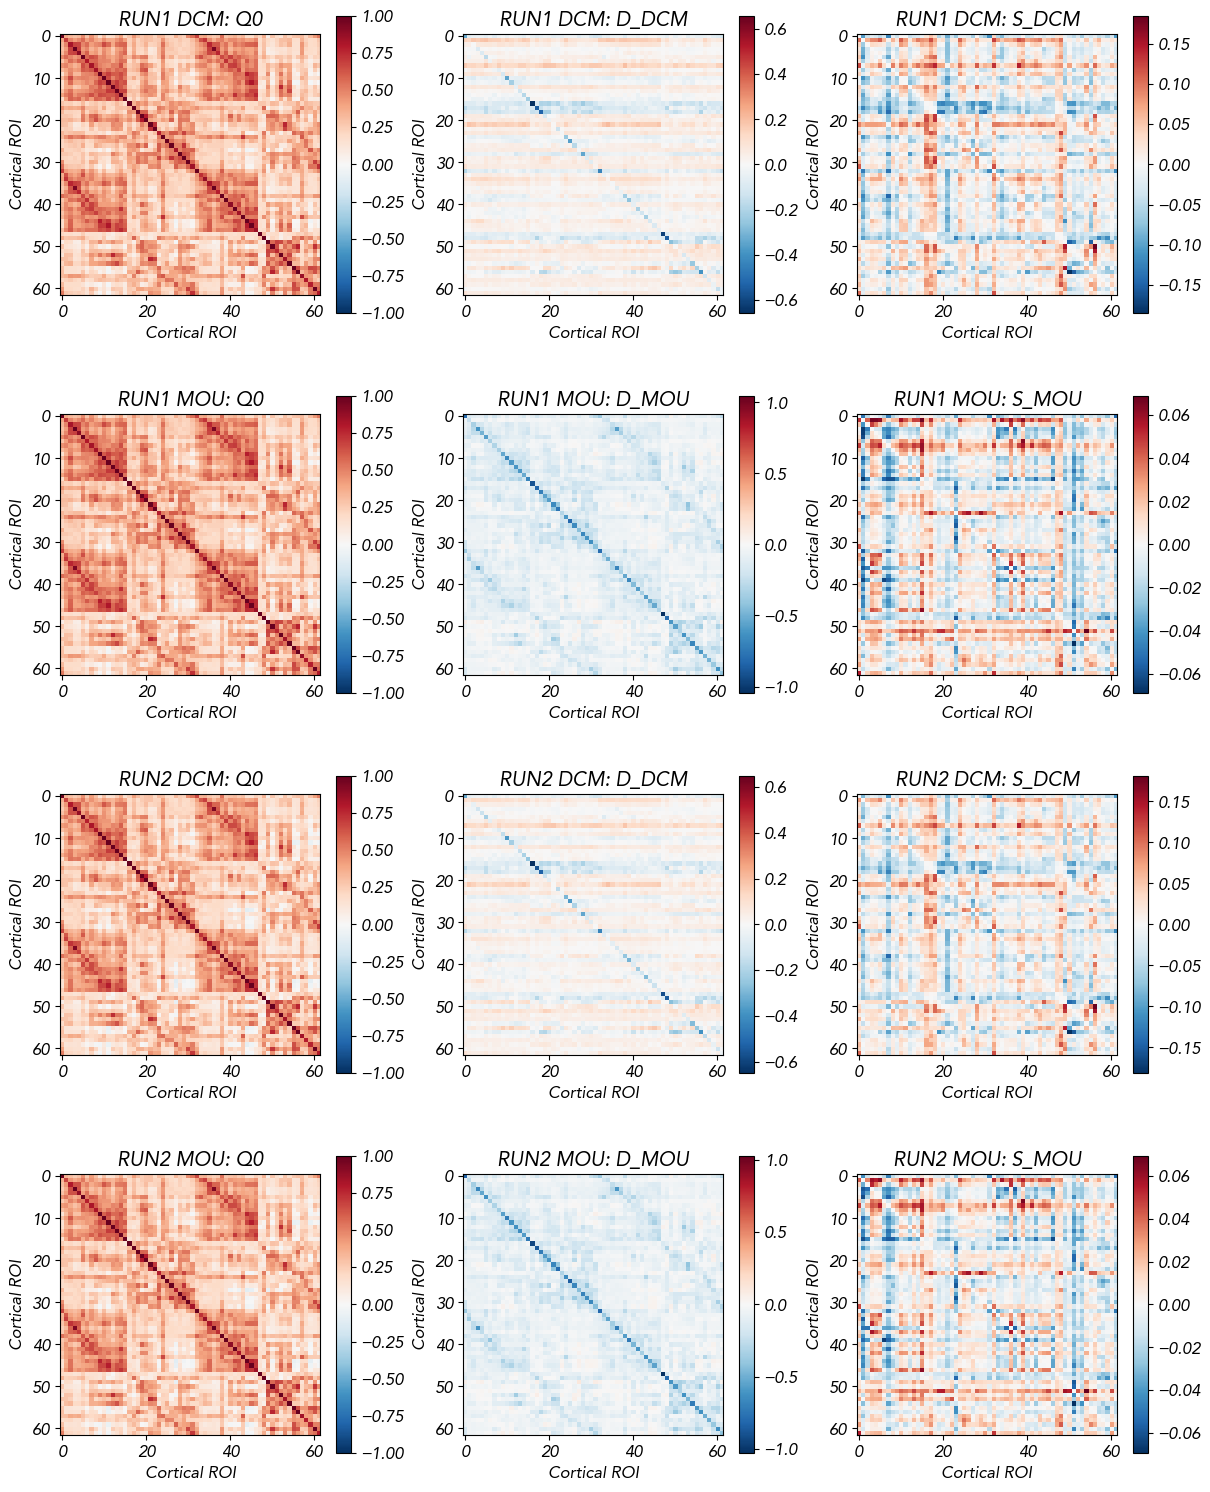

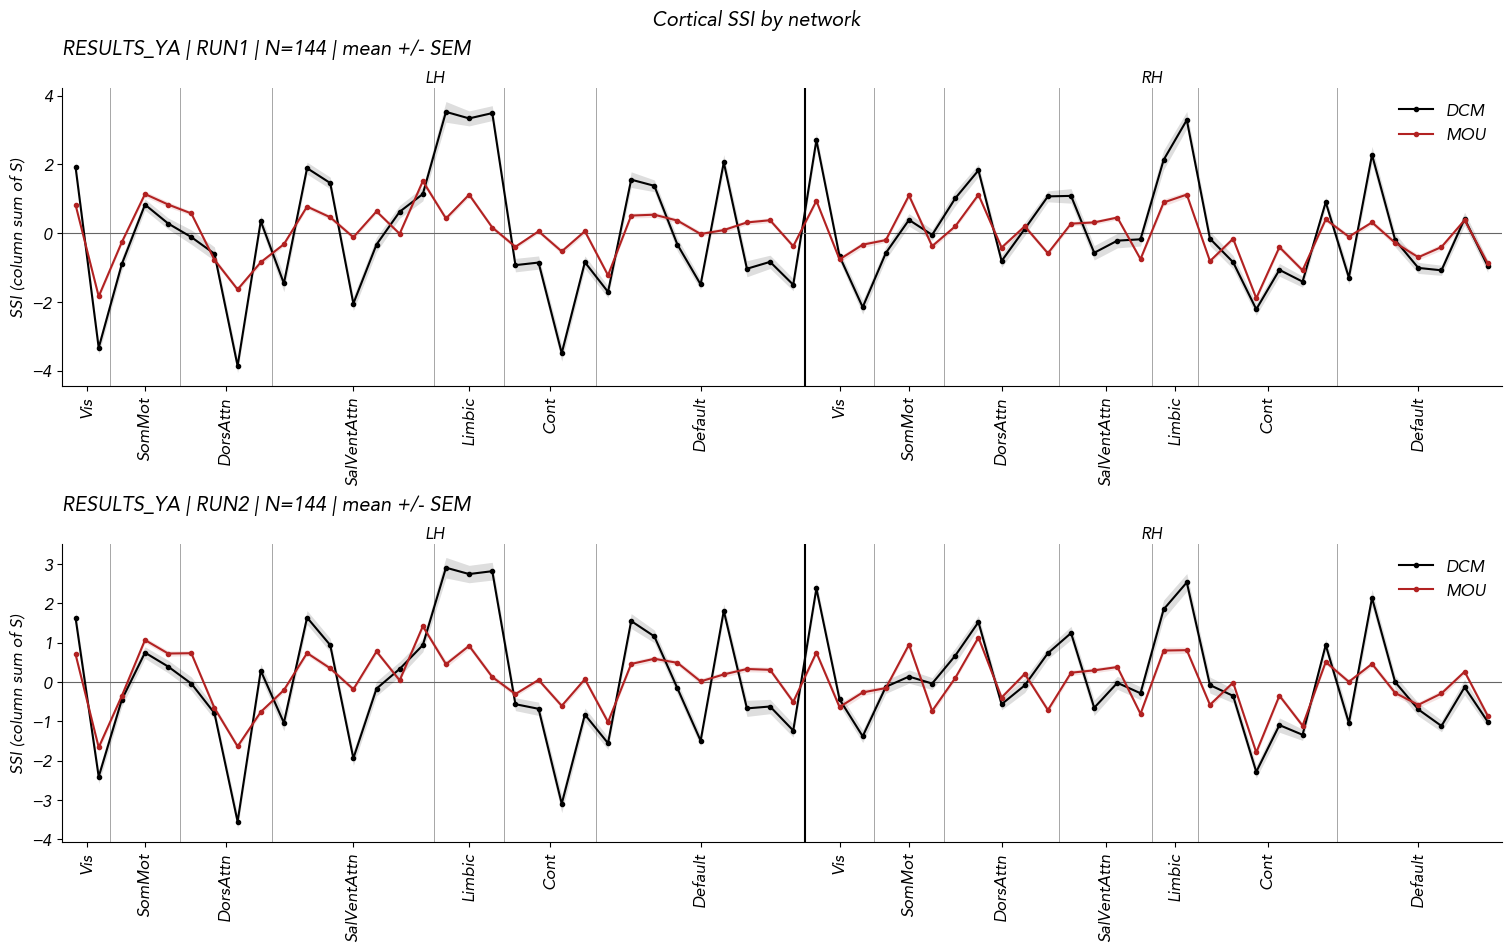

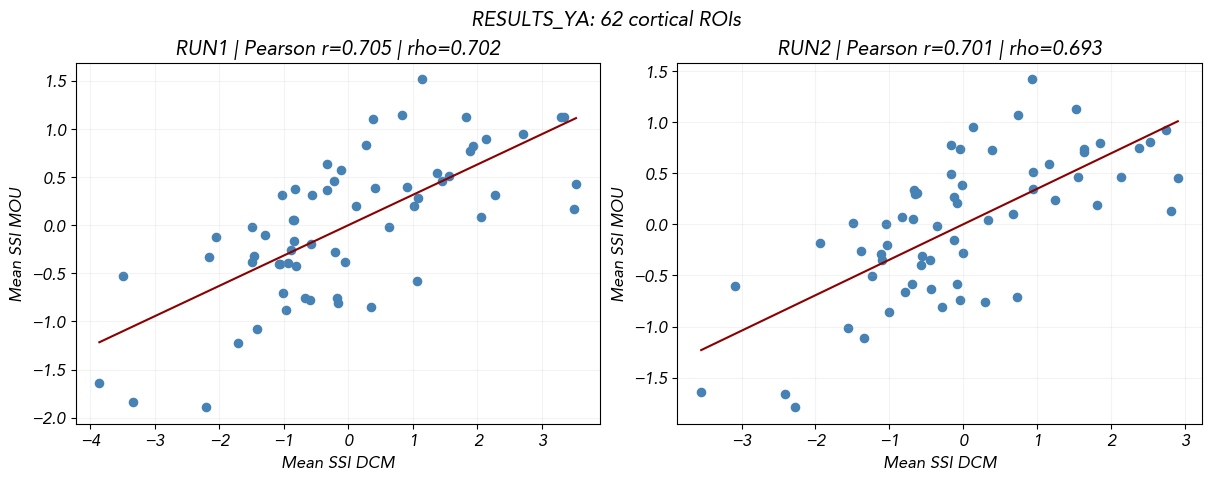

,cohort,run,subjects,ROIs,Pearson_r,Spearman_rho
0,RESULTS_YA,RUN1,144,62,0.704666,0.702198
1,RESULTS_YA,RUN2,144,62,0.700570,0.693183


In [103]:
plot_matrices(main,'RESULTS_YA')
plot_ssi(main,'RESULTS_YA')
main_correlations=plot_correlations(main,'RESULTS_YA')

## 2. DCM TR1 points16 e MOU RUN1 — coorte abbinata

Caricamento diretto di `A` dai file `sub-<ID>.mat_TR1_realData_var11_emo_points16.mat`. I file con A 74×74 vengono ridotti alle prime 62 regioni **prima di D**; quelli 62×62 sono usati integralmente. Si selezionano gli ID con dati BOLD validi e una posizione nel medesimo indice MOU ricostruito. Q0 e MOU RUN1 sono calcolate/selezionate per questa coorte, non si confronta il suo SSI con la media di un'altra coorte. Il report registra dimensioni originali e motivi di esclusione.

In [5]:
tr1_files={}
pattern=re.compile(r'^sub-(\d+)\.mat_TR1_realData_var11_emo_points16\.mat$')
for f in sorted(TR1_ROOT.glob('*TR1*.mat')):
    match=pattern.match(f.name)
    if match:
        sid=match.group(1)
        if sid in tr1_files:raise ValueError(f'Duplicate subject {sid}')
        tr1_files[sid]=f
assert tr1_files,'No TR1 points16 files found'
tr1_ids=[];tr1_audit=[]
for sid,f in sorted(tr1_files.items()):
    reasons=[]
    A=loadmat(f,variable_names=['A']).get('A')
    shape=None if A is None else A.shape
    if shape not in [(62,62),(74,74)]:reasons.append(f'unsupported A shape {shape}')
    elif not np.isfinite(A).all():reasons.append('nonfinite A')
    bfile=bold_path(sid,'RUN1')
    if not bfile.exists():reasons.append('missing BOLD RUN1')
    elif np.load(bfile,mmap_mode='r').shape!=(1200,112):reasons.append('BOLD shape RUN1')
    if sid not in mou_lookup:reasons.append('absent from reconstructed MOU index')
    tr1_audit.append({'subject_id':sid,'file':f.name,'original_A_shape':str(shape),
                      'included':not reasons,'reason':'; '.join(reasons)})
    if not reasons:tr1_ids.append(sid)
tr1={'RUN1':analyze(tr1_ids,'RUN1',tr1_files)}
pd.DataFrame(tr1_audit).to_csv(OUT/'TR1_points16_subject_audit.csv',index=False)
save_cohort(tr1,tr1_ids,'TR1_points16')
print('TR1 points16 files:',len(tr1_files),'included subjects:',len(tr1_ids))
display(pd.DataFrame(tr1_audit).query('not included'))


TR1 points16 files: 145 included subjects: 145


,subject_id,file,original_A_shape,included,reason


In [104]:
plot_matrices(tr1,'TR1_points16')
plot_ssi(tr1,'TR1_points16')
tr1_correlations=plot_correlations(tr1,'TR1_points16')
print('Figures:',FIGURES)
print('Data and audits:',OUT)

NameError: name 'tr1' is not defined

## 3. RESULTS_YA RUN1 — 74 regioni, incluse le sottocorticali

Analisi aggiuntiva, senza cambiare le sezioni corticali e TR1. Si ricalcolano D, S e SSI dalle A, J e Q0 **complete** della prima analisi: nessun taglio a 62. Per la MOU si usa J trasposta. I plot applicano lo stesso ordine dei network ai due modelli. Resta provvisorio l’abbinamento dei soggetti MOU.

RUN1: 144 soggetti, prodotto e SSI su tutte le 74 regioni.
Abbinamento MOU provvisorio: ordine originale degli array non certificato.


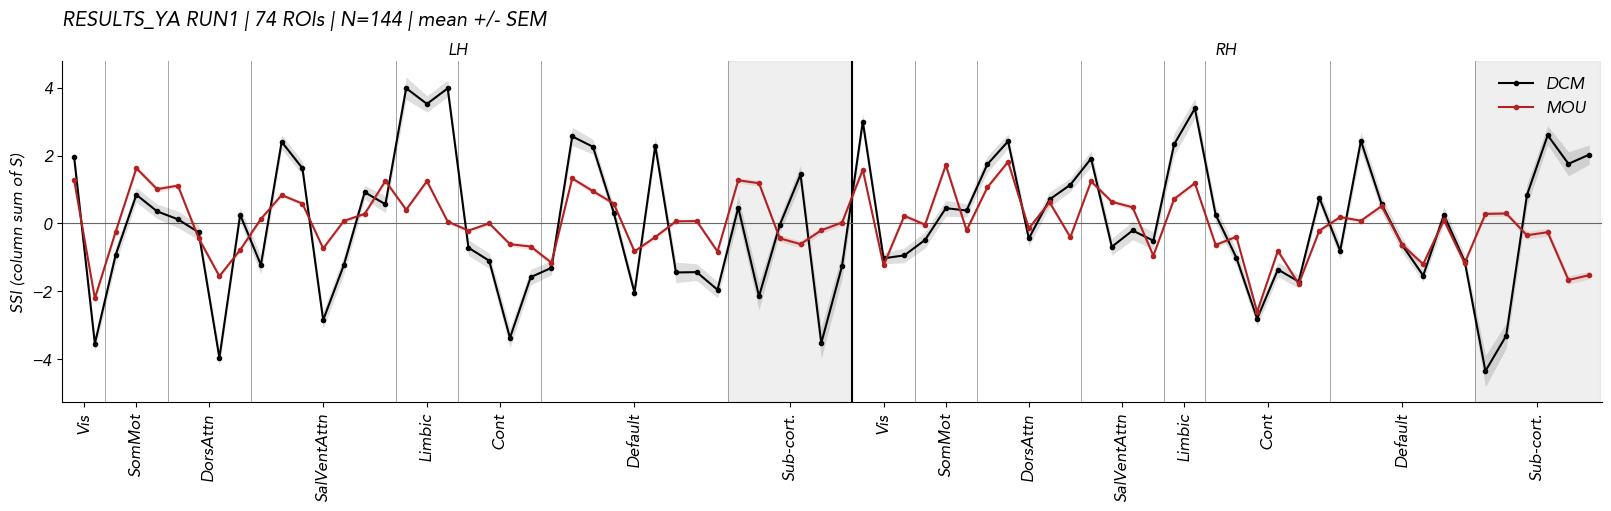

,run,subjects,ROIs,Pearson_r,Spearman_rho
0,RUN1,144,74,0.496726,0.505102


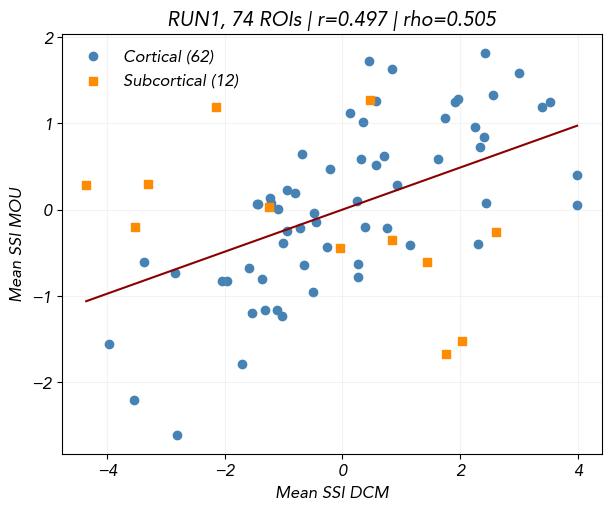

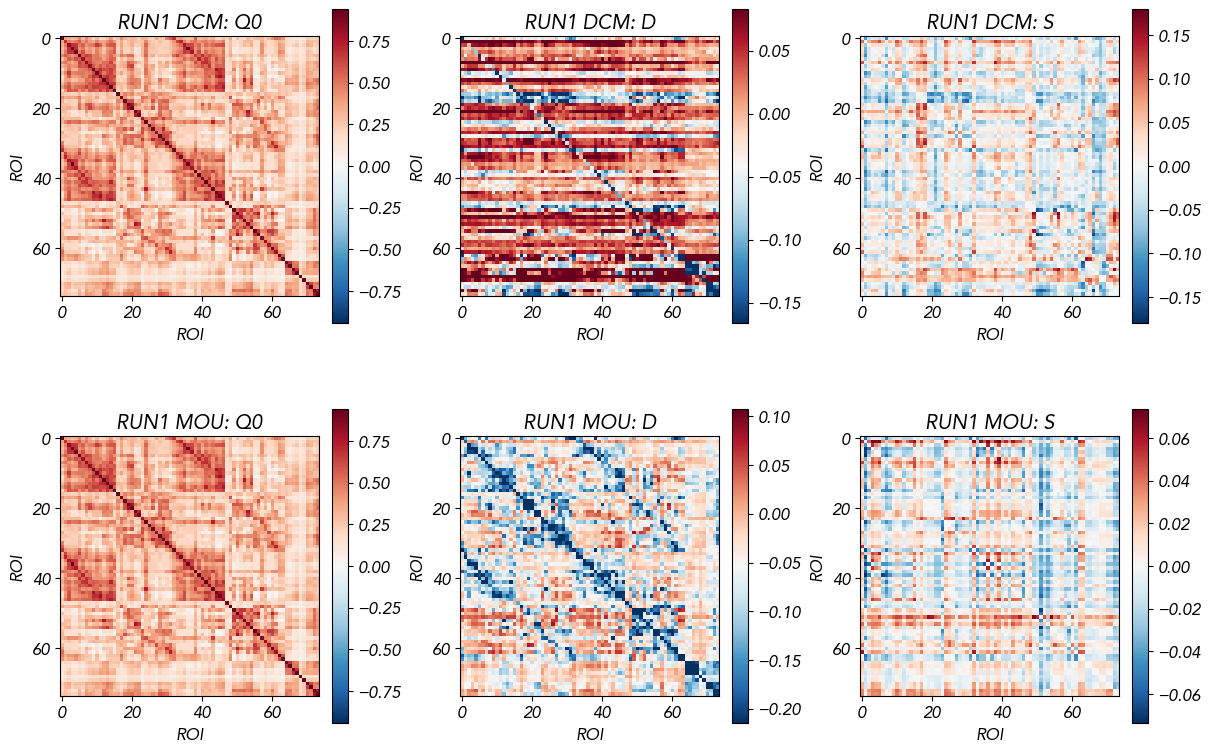

Salvati 3 JPG in: /home/benedetta/Scripts/Insight_project/Figures/SSI_cortical_DCM_MOU


In [97]:
# Cella autonoma: usa A, J e Q0 complete salvate nella prima analisi.
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import pearsonr, spearmanr

full_project=Path('/home/benedetta/Scripts/Insight_project')
full_figures=full_project/'Figures/SSI_cortical_DCM_MOU'
full_figures.mkdir(parents=True,exist_ok=True)
with np.load(full_project/'numpy files/DCM_differential_cross_covariance/differential_cross_covariance_74.npz') as ds, \
     np.load(full_project/'numpy files/MOU_differential_cross_covariance/differential_cross_covariance_74.npz') as ms:
    full_ids=ds['subject_ids'].copy()
    assert np.array_equal(full_ids,ms['subject_ids'])
    full_A=ds['A_RUN1'].copy()
    full_J=ms['J_raw_RUN1'].transpose(0,2,1).copy()
    full_Q0=ds['Q0_RUN1'].copy()
    assert np.array_equal(full_Q0,ms['Q0_RUN1'])
    full_mapping=ds['mapping'].copy()
assert full_A.shape==full_J.shape==full_Q0.shape==(len(full_ids),74,74)
full_results={}
for model,J in [('DCM',full_A),('MOU',full_J)]:
    D=J @ full_Q0
    S=.5*(D-D.transpose(0,2,1))
    SSI=S.sum(axis=1)
    np.testing.assert_allclose(S,-S.transpose(0,2,1),atol=1e-12)
    np.testing.assert_allclose(SSI.sum(axis=1),0,atol=1e-10)
    full_results[model]={'D':D,'S':S,'SSI':SSI}
print(f'RUN1: {len(full_ids)} soggetti, prodotto e SSI su tutte le 74 regioni.')
print('Abbinamento MOU provvisorio: ordine originale degli array non certificato.')

full_labels_file=Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt')
full_labels=[l.split()[1] for l in full_labels_file.read_text().splitlines() if l.strip()]
def full_network(label):
    parts=label.split('_');i=next(i for i,x in enumerate(parts) if x in ['LH','RH'])
    return '_'.join(parts[i:i+2])
full_fine=np.array([full_network(l) for l in full_labels])
full_names=[Counter(full_fine[full_mapping[:100]==roi]).most_common(1)[0][0] for roi in range(1,63)]
full_names=np.array(full_names+['LH_SubCort']*6+['RH_SubCort']*6)
full_net_order=[f'{h}_{n}' for h in ['LH','RH'] for n in ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default','SubCort']]
full_groups=[(n,np.flatnonzero(full_names==n)) for n in full_net_order if np.any(full_names==n)]
full_order=np.concatenate([ix for _,ix in full_groups])
assert np.array_equal(np.sort(full_order),np.arange(74))
full_sizes=np.array([len(ix) for _,ix in full_groups]);full_starts=np.r_[0,np.cumsum(full_sizes)[:-1]]
full_centers=full_starts+(full_sizes-1)/2
full_left=sum(len(ix) for n,ix in full_groups if n.startswith('LH_'))
full_font=full_project/'Notebook figure/Avenir-Oblique.ttf'
full_style={'font.size':12}
if full_font.exists():
    font_manager.fontManager.addfont(str(full_font))
    full_style['font.family']=font_manager.FontProperties(fname=str(full_font)).get_name()
with plt.rc_context(full_style):
    full_fig,full_ax=plt.subplots(figsize=(16,5),constrained_layout=True)
    for model,color in [('DCM','black'),('MOU','firebrick')]:
        values=full_results[model]['SSI'][:,full_order]
        mean=values.mean(axis=0);sem=values.std(axis=0,ddof=1)/np.sqrt(len(values))
        full_ax.plot(np.arange(74),mean,'-o',color=color,markersize=3,label=model)
        full_ax.fill_between(np.arange(74),mean-sem,mean+sem,color=color,alpha=.13,lw=0)
    for end in np.cumsum(full_sizes)[:-1]:full_ax.axvline(end-.5,color='.65',lw=.7,zorder=0)
    for start,size,(name,_) in zip(full_starts,full_sizes,full_groups):
        if name.endswith('SubCort'):full_ax.axvspan(start-.5,start+size-.5,color='.6',alpha=.15,zorder=0)
    full_ax.axvline(full_left-.5,color='black',lw=1.5,zorder=0)
    full_ax.axhline(0,color='.4',lw=.8,zorder=0)
    full_ax.set_xticks(full_centers)
    full_ax.set_xticklabels([n.split('_',1)[1].replace('SubCort','Sub-cort.') for n,_ in full_groups],rotation=90)
    for center,hemi in [((full_left-1)/2,'LH'),(full_left+(74-full_left-1)/2,'RH')]:
        full_ax.text(center,1.02,hemi,transform=full_ax.get_xaxis_transform(),ha='center',fontweight='bold')
    full_ax.set(xlim=(-.6,73.6),ylabel='SSI (column sum of S)')
    full_ax.set_title(f'RESULTS_YA RUN1 | 74 ROIs | N={len(full_ids)} | mean +/- SEM',loc='left',pad=26)
    full_ax.legend(frameon=False)
    full_ax.spines['top'].set_visible(False);full_ax.spines['right'].set_visible(False)
    full_fig.savefig(full_figures/'RESULTS_YA_RUN1_74_SSI_networks.jpg',dpi=300,bbox_inches='tight')
    plt.show()

full_x=full_results['DCM']['SSI'].mean(axis=0)
full_y=full_results['MOU']['SSI'].mean(axis=0)
full_r=pearsonr(full_x,full_y)[0];full_rho=spearmanr(full_x,full_y)[0]
full_summary=pd.DataFrame([{'run':'RUN1','subjects':len(full_ids),'ROIs':74,'Pearson_r':full_r,'Spearman_rho':full_rho}])
display(full_summary)
with plt.rc_context(full_style):
    full_scatter,full_scax=plt.subplots(figsize=(6,5),constrained_layout=True)
    full_scax.scatter(full_x[:62],full_y[:62],color='steelblue',label='Cortical (62)')
    full_scax.scatter(full_x[62:],full_y[62:],color='darkorange',marker='s',label='Subcortical (12)')
    slope,intercept=np.polyfit(full_x,full_y,1);xx=np.linspace(full_x.min(),full_x.max(),100)
    full_scax.plot(xx,slope*xx+intercept,color='darkred')
    full_scax.set(xlabel='Mean SSI DCM',ylabel='Mean SSI MOU',title=f'RUN1, 74 ROIs | r={full_r:.3f} | rho={full_rho:.3f}')
    full_scax.legend(frameon=False);full_scax.grid(alpha=.15)
    full_scatter.savefig(full_figures/'RESULTS_YA_RUN1_74_SSI_correlations.jpg',dpi=300,bbox_inches='tight')
    plt.show()
import sys
sys.path.append('..')
from my_module import *
with plt.rc_context(full_style):
    full_heatmap,full_axes=plt.subplots(2,3,figsize=(12,8),constrained_layout=True)
    for row,model in enumerate(['DCM','MOU']):
        for col,(key,values) in enumerate([('Q0',full_Q0),('D',full_results[model]['D']),('S',full_results[model]['S'])]):
            mean=values.mean(axis=0);lim=np.max(np.abs(dediag(mean)))
            #print(mean.shape)
            lim1 = lim
            lim2 = lim
            if key == 'D': 
                lim1 = 0.4*np.max(np.abs(dediag(mean)))
                lim2 = 0.2*np.max(np.abs(dediag(mean)))
                
            im=full_axes[row,col].imshow(mean,cmap='RdBu_r',vmin=-lim1,vmax=lim2)
            full_axes[row,col].set(title=f'RUN1 {model}: {key}',xlabel='ROI',ylabel='ROI')
            full_heatmap.colorbar(im,ax=full_axes[row,col],shrink=.8)
    full_heatmap.savefig(full_figures/'RESULTS_YA_RUN1_74_matrices.jpg',dpi=250,bbox_inches='tight')
    plt.show()
print('Salvati 3 JPG in:',full_figures)


## 4. MOU: SSI nativo, poi aggregazione 100→62 e 112→74

RUN1, stessi 144 soggetti della prima analisi. Come Figure 5: `EC_matrix_HCP1_100.npy` (112×112), J trasposta, FC Pearson filtrata a risoluzione nativa, D=J.T@Q0, S=(D-D.T)/2, SSI=S.sum(axis=0). Solo dopo si aggregano **per media** le 100 componenti corticali in 62. Nel caso 112→74, le 12 componenti sottocorticali sono mantenute individualmente: nessuna regione viene eliminata.

Confronti separati, dimensionalmente coerenti: 100→62 contro MOU nativa 62 e DCM62; 112→74 contro MOU nativa74 e DCM74. Tutti i prodotti mantengono le diagonali. Network come Figure 5; il riordino interessa solo i plot.

L'abbinamento MOU resta provvisorio. Questi sono fit a risoluzioni diverse: eventuali differenze non isolano soltanto l'ordine di aggregazione. Figure 5 poteva usare tutti i 1013 soggetti; qui si mantiene la coorte comune per confrontabilità. L'aggregazione per media non conserva necessariamente la somma zero dell'SSI nativo.

,ROIs,profile_1,profile_2,Pearson_r,Spearman_rho
0,62,DCM,MOU SSI 100 to 62,0.547175,0.544408
1,62,MOU native 62,MOU SSI 100 to 62,0.583992,0.569641
2,74,DCM,MOU SSI 112 to 74,0.237242,0.313676
3,74,MOU native 74,MOU SSI 112 to 74,0.669695,0.649463


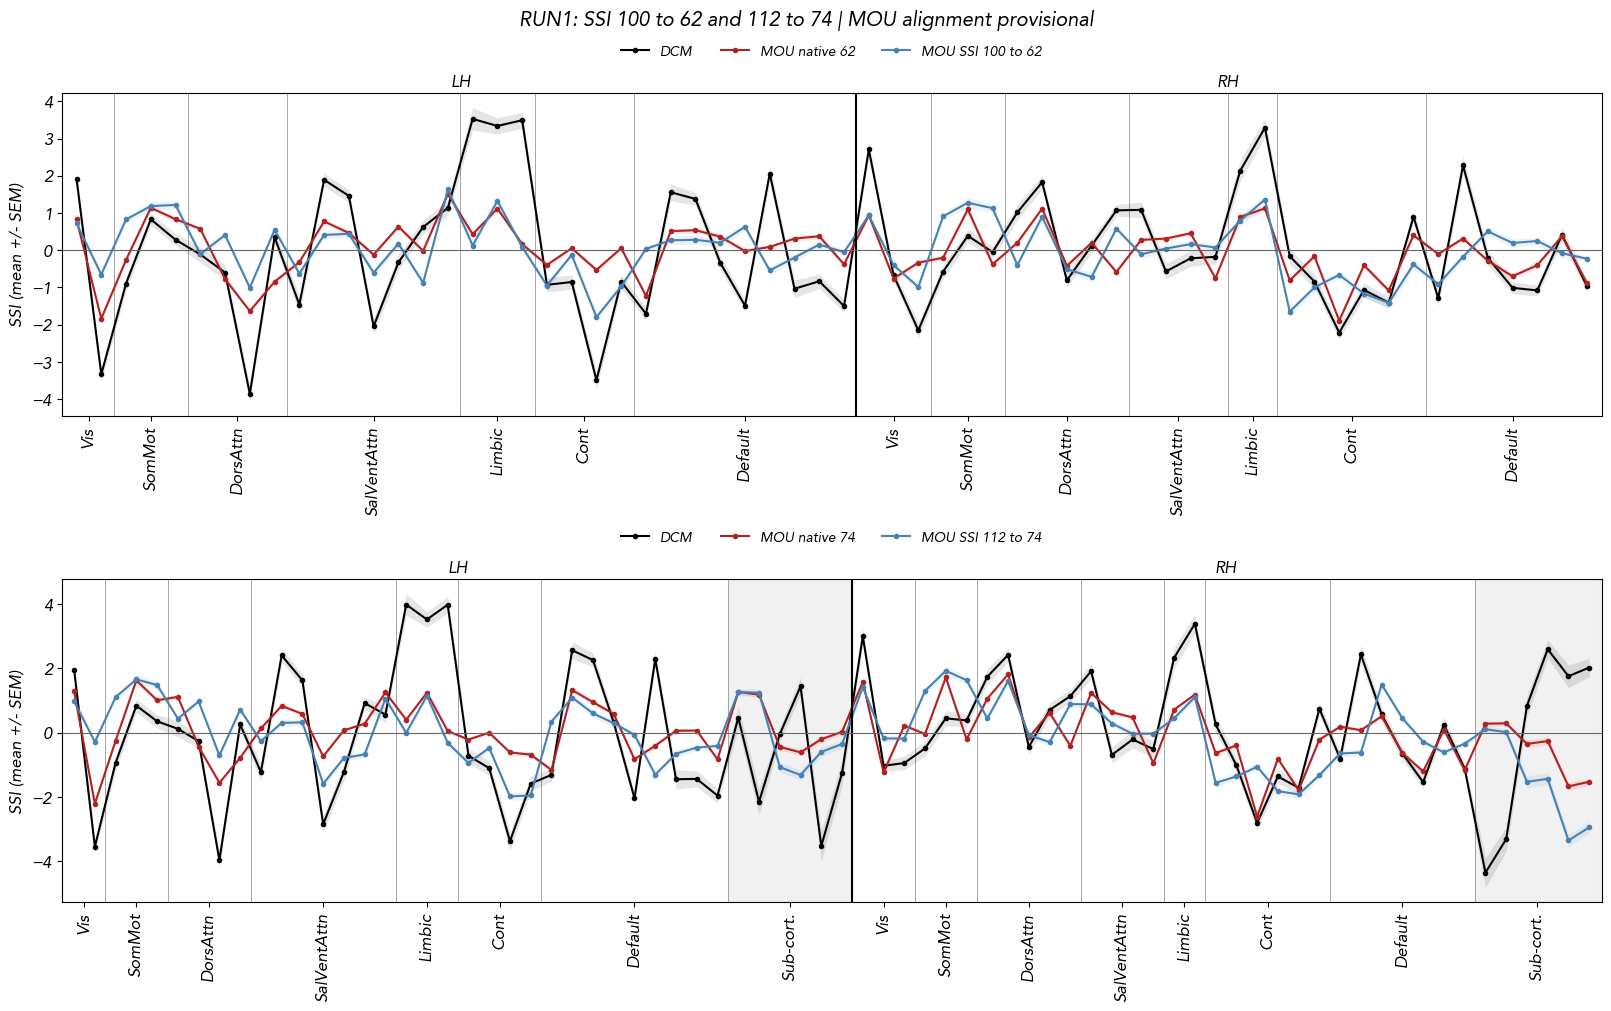

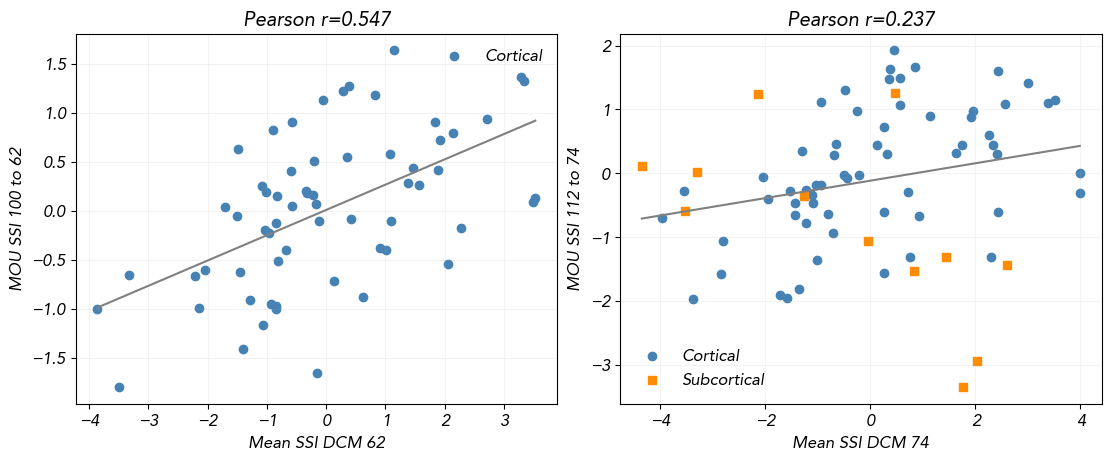

In [1]:
# Autonoma: confronto RUN1 sulla medesima coorte della sezione RESULTS_YA.
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from scipy import signal
from scipy.io import loadmat
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits
threadpool_limits(limits=4)
pa_project=Path('/home/benedetta/Scripts/Insight_project')
pa_out=pa_project/'numpy files/SSI_cortical_DCM_MOU'
pa_figdir=pa_project/'Figures/SSI_cortical_DCM_MOU'
with np.load(pa_out/'RESULTS_YA_62.npz') as z:
    pa_ids=z['subject_ids'].copy()
    pa_indices=z['mou_source_indices'].copy()
    pa_old=z['SSI_MOU_RUN1'].copy()
    pa_dcm=z['SSI_DCM_RUN1'].copy()
pa_map_full=loadmat(pa_project/'clust_idx_LEMON.mat')['clust_idx_LEMON'].ravel()
pa_map=pa_map_full[:100]
pa_W74=(pa_map_full[:,None]==np.arange(1,75)).astype(float)
pa_W74/=pa_W74.sum(axis=0)
pa_W=(pa_map[:,None]==np.arange(1,63)).astype(float)
pa_W/=pa_W.sum(axis=0)
pa_raw=np.load(pa_project/'numpy files/EC_matrix_HCP1_100.npy',mmap_mode='r')
assert pa_raw.shape[1:]==(112,112)
pa_b,pa_a=signal.butter(2,[.01,.1],btype='bandpass',fs=1/.72)
pa_values={100:[],112:[]}
pa_native={100:[],112:[]}
for sid,idx in zip(pa_ids,pa_indices):
    X=np.load(Path('/home/benedetta/hcp_parcellated')/sid/f'{sid}_REST1_LR_Schaefer100+AAL.npy')
    assert X.shape==(1200,112)
    FC=np.corrcoef(signal.filtfilt(pa_b,pa_a,X,axis=0),rowvar=False)
    for size in [100,112]:
        J=np.array(pa_raw[idx,:size,:size]).T
        D=J @ FC[:size,:size]
        S=.5*(D-D.T)
        SSI=S.sum(axis=0)
        np.testing.assert_allclose(S,-S.T,atol=1e-12)
        np.testing.assert_allclose(SSI.sum(),0,atol=1e-9)
        # Figure 5: mean degli SSI corticali entro ogni parcella aggregata.
        reduced=SSI @ (pa_W if size==100 else pa_W74)
        current_map=pa_map if size==100 else pa_map_full
        reference=np.array([SSI[current_map==roi].mean() for roi in range(1,63 if size==100 else 75)])
        np.testing.assert_allclose(reduced,reference,atol=1e-12)
        pa_native[size].append(SSI)
        pa_values[size].append(reduced)
pa_values={k:np.stack(v) for k,v in pa_values.items()}
pa_native={k:np.stack(v) for k,v in pa_native.items()}

with np.load(pa_project/'numpy files/DCM_differential_cross_covariance/differential_cross_covariance_74.npz') as d, np.load(pa_project/'numpy files/MOU_differential_cross_covariance/differential_cross_covariance_74.npz') as m:
    assert np.array_equal(pa_ids,d['subject_ids']) and np.array_equal(pa_ids,m['subject_ids'])
    Q=d['Q0_RUN1'];np.testing.assert_array_equal(Q,m['Q0_RUN1'])
    DD=d['A_RUN1']@Q;DM=m['J_raw_RUN1'].transpose(0,2,1)@Q
    pa_dcm74=(.5*(DD-DD.transpose(0,2,1))).sum(axis=1)
    pa_mou74=(.5*(DM-DM.transpose(0,2,1))).sum(axis=1)
pa_sets={62:{'DCM':pa_dcm,'MOU native 62':pa_old,'MOU SSI 100 to 62':pa_values[100]},
         74:{'DCM':pa_dcm74,'MOU native 74':pa_mou74,'MOU SSI 112 to 74':pa_values[112]}}
pa_rows=[]
for size,profiles in pa_sets.items():
    new_key=list(profiles)[-1]
    for key in list(profiles)[:2]:
        x=profiles[key].mean(axis=0);y=profiles[new_key].mean(axis=0)
        assert len(x)==len(y)==size
        pa_rows.append({'ROIs':size,'profile_1':key,'profile_2':new_key,'Pearson_r':pearsonr(x,y)[0],'Spearman_rho':spearmanr(x,y)[0]})
pa_correlations=pd.DataFrame(pa_rows);display(pa_correlations)
pa_correlations.to_csv(pa_out/'SSI_postaggregation_RUN1_correlations.csv',index=False)
np.savez_compressed(pa_out/'SSI_postaggregation_RUN1.npz',subject_ids=pa_ids,mou_source_indices=pa_indices,
                    SSI100=pa_native[100],SSI112=pa_native[112],SSI100_to62=pa_values[100],
                    SSI112_to74=pa_values[112],SSI_MOU62=pa_old,SSI_DCM62=pa_dcm,
                    SSI_MOU74=pa_mou74,SSI_DCM74=pa_dcm74,mapping=pa_map_full)
pa_labels=Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt')
pa_names=[line.split()[1] for line in pa_labels.read_text().splitlines() if line.strip()]
def pa_net(label):
    parts=label.split('_');i=next(i for i,x in enumerate(parts) if x in ['LH','RH'])
    return '_'.join(parts[i:i+2])
pa_fine=np.array([pa_net(label) for label in pa_names])
pa_nets62=[Counter(pa_fine[pa_map==i]).most_common(1)[0][0] for i in range(1,63)]
pa_style={'font.size':12}
pa_font=pa_project/'Notebook figure/Avenir-Oblique.ttf'
if pa_font.exists():
    font_manager.fontManager.addfont(str(pa_font))
    pa_style['font.family']=font_manager.FontProperties(fname=str(pa_font)).get_name()
with plt.rc_context(pa_style):
    pa_fig,pa_axes=plt.subplots(2,1,figsize=(16,10),constrained_layout=True)
    for ax,(size,profiles) in zip(pa_axes,pa_sets.items()):
        nets=np.array(pa_nets62+(['LH_SubCort']*6+['RH_SubCort']*6 if size==74 else []))
        network_order=[f'{h}_{v}' for h in ['LH','RH'] for v in ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default','SubCort']]
        groups=[(v,np.flatnonzero(nets==v)) for v in network_order if np.any(nets==v)]
        order=np.concatenate([ix for _,ix in groups]);assert np.array_equal(np.sort(order),np.arange(size))
        sizes=np.array([len(ix) for _,ix in groups]);starts=np.r_[0,np.cumsum(sizes)[:-1]]
        left=sum(len(ix) for v,ix in groups if v.startswith('LH_'))
        for (key,values),color in zip(profiles.items(),['black','firebrick','steelblue']):
            v=values[:,order];mean=v.mean(axis=0);sem=v.std(axis=0,ddof=1)/np.sqrt(len(v))
            ax.plot(np.arange(size),mean,'-o',color=color,ms=3,label=key)
            ax.fill_between(np.arange(size),mean-sem,mean+sem,color=color,alpha=.10,lw=0)
        for bound in np.cumsum(sizes)[:-1]:ax.axvline(bound-.5,color='.65',lw=.7,zorder=0)
        for start,num,(name,_) in zip(starts,sizes,groups):
            if name.endswith('SubCort'):ax.axvspan(start-.5,start+num-.5,color='.6',alpha=.13,zorder=0)
        ax.axvline(left-.5,color='black',lw=1.5);ax.axhline(0,color='.4',lw=.8)
        ax.set_xticks(starts+(sizes-1)/2);ax.set_xticklabels([v.split('_',1)[1].replace('SubCort','Sub-cort.') for v,_ in groups],rotation=90)
        ax.set(xlim=(-.6,size-.4),ylabel='SSI (mean +/- SEM)')
        for center,hemi in [((left-1)/2,'LH'),(left+(size-left-1)/2,'RH')]:
            ax.text(center,1.02,hemi,transform=ax.get_xaxis_transform(),ha='center')
        ax.legend(frameon=False,ncol=3,loc='upper center',bbox_to_anchor=(.5,1.19),fontsize=10)
    pa_fig.suptitle('RUN1: SSI 100 to 62 and 112 to 74 | MOU alignment provisional')
    pa_fig.savefig(pa_figdir/'RUN1_SSI_postaggregation_networks.jpg',dpi=300,bbox_inches='tight');plt.show()
with plt.rc_context(pa_style):
    pa_fig2,pa_ax2=plt.subplots(1,2,figsize=(11,4.5),constrained_layout=True)
    for ax,(size,profiles) in zip(pa_ax2,pa_sets.items()):
        key=list(profiles)[-1];x=profiles['DCM'].mean(axis=0);y=profiles[key].mean(axis=0)
        ax.scatter(x[:62],y[:62],color='steelblue',label='Cortical')
        if size==74:ax.scatter(x[62:],y[62:],color='darkorange',marker='s',label='Subcortical')
        slope,intercept=np.polyfit(x,y,1);xx=np.linspace(x.min(),x.max(),100)
        ax.plot(xx,slope*xx+intercept,color='gray')
        ax.set(xlabel=f'Mean SSI DCM {size}',ylabel=key,title=f'Pearson r={pearsonr(x,y)[0]:.3f}')
        ax.legend(frameon=False);ax.grid(alpha=.15)
    pa_fig2.savefig(pa_figdir/'RUN1_SSI_postaggregation_DCM_correlations.jpg',dpi=300,bbox_inches='tight');plt.show()


## Figure paper: DCM TR1 vs MOU completo — 62 corticali

Confronto richiesto: DCM TR1 points16 RUN1 (145 soggetti) vs MOU `EC_matrix_HCP1_74.npy` limitata alle 62 corticali (tutti i 1013 soggetti). **Il prodotto D e la somma SSI avvengono su 62×62 in entrambi i modelli**, senza contributi sottocorticali. MOU trasposta. Q0 mantiene la procedura FC Pearson filtrata, ridotta per media dei blocchi.

Curve = medie e bande ±SEM tra soggetti, ordinate per network maggioritario come Figure 5. I network servono a organizzare le 62 parcelle; non si stanno mostrando soltanto 14 medie di network. Scatter e correlazioni fra i 62 valori regionali medi; le coorti differiscono deliberatamente. Il confronto non isola quindi unicamente la differenza tra modelli.

L'ordine delle righe MOU rispetto ai soggetti/FC è ancora assunto, non certificato. Questa limitazione resta da risolvere prima di usare il confronto come risultato definitivo nel paper. I titoli delle figure sono mantenuti semplici come richiesto.

,DCM_subjects,MOU_subjects,ROIs,Pearson_r,Spearman_rho
0,145,1013,62,0.724585,0.708444


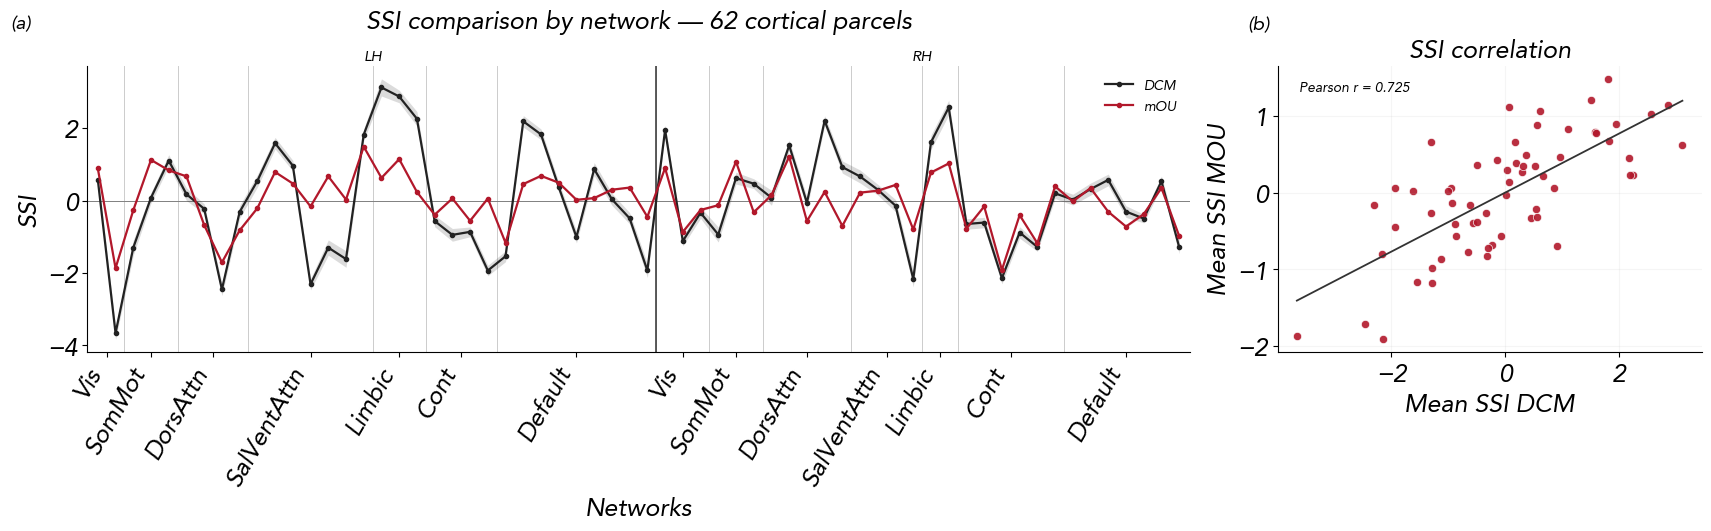

Saved combined figure: /home/benedetta/Scripts/Insight_project/Figures/SSI_paper_62/SSI_DCM_TR1_vs_MOU1013_combined_62.jpg


In [112]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy import signal
from scipy.stats import pearsonr,spearmanr
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits
threadpool_limits(limits=4)
pp=Path('/home/benedetta/Scripts/Insight_project')
figdir=pp/'Figures/SSI_paper_62'
figdir.mkdir(parents=True,exist_ok=True)
cache=pp/'numpy files/SSI_cortical_DCM_MOU/MOU_all1013_RUN1_cortical62.npz'
with np.load(pp/'numpy files/SSI_cortical_DCM_MOU/TR1_points16_62.npz') as d:
    paper_dcm=d['SSI_DCM_RUN1'].copy();paper_dcm_ids=d['subject_ids'].copy()
assert paper_dcm.shape[1]==62
root=Path('/home/benedetta/hcp_parcellated')
ids=[]
for folder in sorted(root.iterdir(),key=lambda f:f.name):
    sid=folder.name
    fs=[folder/f'{sid}_REST{k}_LR_Schaefer100+AAL.npy' for k in (1,2)]
    if all(f.exists() for f in fs) and all(np.load(f,mmap_mode='r').shape[0]==1200 for f in fs):ids.append(sid)
ids=np.array(ids)
raw=np.load(pp/'numpy files/EC_matrix_HCP1_74.npy',mmap_mode='r')
assert raw.shape==(len(ids),74,74) and len(ids)==1013
mapping=loadmat(pp/'clust_idx_LEMON.mat')['clust_idx_LEMON'].ravel()[:100]
W=(mapping[:,None]==np.arange(1,63)).astype(float);W/=W.sum(axis=0)
if cache.exists():
    with np.load(cache) as z:
        assert np.array_equal(ids,z['subject_ids_assumed'])
        paper_mou=z['SSI'].copy()
else:
    b,a=signal.butter(2,[.01,.1],btype='bandpass',fs=1/.72)
    paper_mou=[]
    for idx,sid in enumerate(ids):
        X=np.load(root/sid/f'{sid}_REST1_LR_Schaefer100+AAL.npy')[:,:100]
        assert X.shape==(1200,100)
        Q=W.T @ np.corrcoef(signal.filtfilt(b,a,X,axis=0),rowvar=False) @ W
        J=np.array(raw[idx,:62,:62]).T
        D=J @ Q;S=.5*(D-D.T)
        assert np.isfinite(S).all()
        np.testing.assert_allclose(S.sum(),0,atol=1e-9)
        paper_mou.append(S.sum(axis=0))
    paper_mou=np.stack(paper_mou)
    np.savez_compressed(cache,SSI=paper_mou,subject_ids_assumed=ids,mapping=mapping,
                        mou_alignment_verified=False,formula='D=J62.T@Q062; S=(D-D.T)/2; SSI=S.sum(axis=0)')
assert paper_mou.shape==(1013,62)
x=paper_dcm.mean(axis=0);y=paper_mou.mean(axis=0)
r=pearsonr(x,y)[0];rho=spearmanr(x,y)[0]
paper_stats=pd.DataFrame([{'DCM_subjects':len(paper_dcm),'MOU_subjects':len(paper_mou),'ROIs':62,'Pearson_r':r,'Spearman_rho':rho}])
display(paper_stats)
paper_stats.to_csv(figdir/'SSI_correlation_statistics.csv',index=False)
labels=Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt')
names=[l.split()[1] for l in labels.read_text().splitlines() if l.strip()]
def network(label):
    parts=label.split('_');i=next(i for i,v in enumerate(parts) if v in ['LH','RH'])
    return '_'.join(parts[i:i+2])
fine=np.array([network(l) for l in names])
nets=np.array([Counter(fine[mapping==i]).most_common(1)[0][0] for i in range(1,63)])
netorder=[f'{h}_{v}' for h in ['LH','RH'] for v in ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']]
groups=[(v,np.flatnonzero(nets==v)) for v in netorder if np.any(nets==v)]
order=np.concatenate([ix for _,ix in groups]);assert np.array_equal(np.sort(order),np.arange(62))
sizes=np.array([len(ix) for _,ix in groups]);starts=np.r_[0,np.cumsum(sizes)[:-1]]
centers=starts+(sizes-1)/2;left=sum(len(ix) for v,ix in groups if v.startswith('LH_'))
style={'font.size':18,'axes.titlesize':18,'axes.labelsize':18,'pdf.fonttype':42,'ps.fonttype':42}
font=pp/'Notebook figure/Avenir-Oblique.ttf'
if font.exists():
    font_manager.fontManager.addfont(str(font));style['font.family']=font_manager.FontProperties(fname=str(font)).get_name()
with plt.rc_context(style):
    paper_combined,(ax,ax_corr)=plt.subplots(1,2,figsize=(17,5.2),
        gridspec_kw={'width_ratios':[2.6,1]},constrained_layout=True)
    for vals,label,color in [(paper_dcm,'DCM','#222222'),(paper_mou,'mOU','#b2182b')]:
        mean=vals.mean(axis=0)[order];sem=(vals.std(axis=0,ddof=1)/np.sqrt(len(vals)))[order]
        ax.plot(np.arange(62),mean,'-o',color=color,ms=3,lw=1.6,label=label)
        ax.fill_between(np.arange(62),mean-sem,mean+sem,color=color,alpha=.16,lw=0)
    for end in np.cumsum(sizes)[:-1]:ax.axvline(end-.5,color='.8',lw=.7,zorder=0)
    ax.axvline(left-.5,color='.25',lw=1.2,zorder=0);ax.axhline(0,color='.5',lw=.7,zorder=0)
    ax.set_xticks(centers);ax.set_xticklabels([v.split('_',1)[1] for v,_ in groups],rotation=60,ha='right')
    for center,hemi in [((left-1)/2,'LH'),(left+(62-left-1)/2,'RH')]:
        ax.text(center,1.02,hemi,transform=ax.get_xaxis_transform(),ha='center',fontsize=11)
    ax.set(xlim=(-.6,61.6),ylabel='SSI',xlabel='Networks')
    ax.set_title('SSI comparison by network — 62 cortical parcels',pad=27)
    ax.legend(frameon=False,loc='best',fontsize=10)
    ax_corr.scatter(x,y,s=35,facecolor='#b2182b',edgecolor='white',linewidth=.5,alpha=.9)
    slope,intercept=np.polyfit(x,y,1);xx=np.linspace(x.min(),x.max(),100)
    ax_corr.plot(xx,slope*xx+intercept,color='#333333',lw=1.3)
    ax_corr.text(.05,.95,f'Pearson r = {r:.3f}',transform=ax_corr.transAxes,va='top',fontsize=10)
    ax_corr.set(xlabel='Mean SSI DCM',ylabel='Mean SSI MOU',title='SSI correlation')
    ax_corr.grid(alpha=.12)
    for axis,label in [(ax,'(a)'),(ax_corr,'(b)')]:
        axis.spines['top'].set_visible(False);axis.spines['right'].set_visible(False)
        axis.text(-.07,1.13,label,transform=axis.transAxes,fontsize=14)
    combined_path=figdir/'SSI_DCM_TR1_vs_MOU1013_combined_62.jpg'
    paper_combined.savefig(combined_path,dpi=400,bbox_inches='tight')
    plt.show()
print('Saved combined figure:',combined_path)


In [106]:
#ls /home/benedetta

In [109]:
plt.rcParams['font.size'] =25

In [117]:
len(matrix_indices)


144

## Correlazione tra entries DCM e MOU — corticali, RUN1

Una correlazione Pearson per soggetto fra tutte le 62×61 entries fuori diagonale: `A_DCM[:62,:62]` vs `J_MOU[:62,:62].T`. DCM dal cache RESULTS_YA, originariamente `/readonly/insights/RESULTS_YA_new_1000`; stessa selezione di soggetti della sezione principale, RUN1. Nessuna FC o SSI usata. **Abbinamento MOU provvisorio:** gli ID delle righe MOU sono ricostruiti, non verificati da metadati originali; i risultati dipendono da questa assunzione.

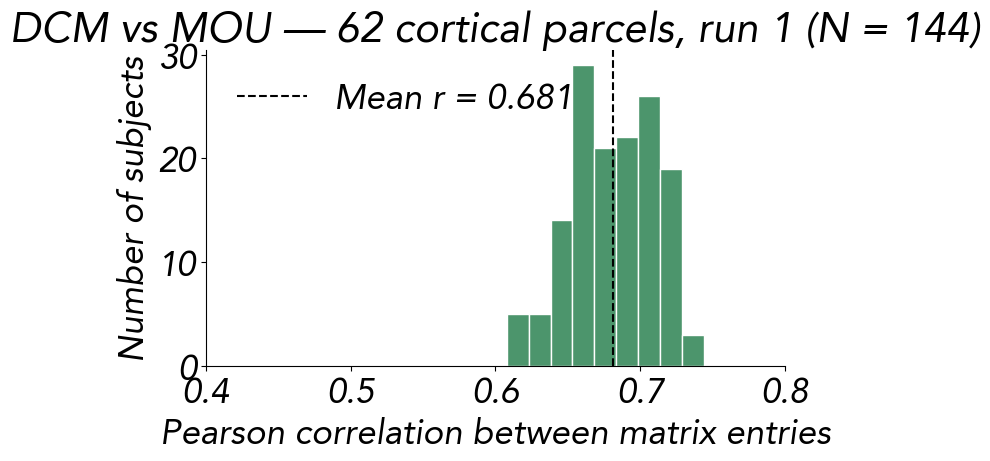

N = 144; mean r = 0.681438; median r = 0.680551; range = [0.607982, 0.743998]
Off-diagonal directed entries per subject: 3782; excluded invalid pairs: 0
MOU subject alignment verified: False


In [115]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

project = Path('/home/benedetta/Scripts/Insight_project')
cache = project / 'numpy files/SSI_cortical_DCM_MOU/RESULTS_YA_62.npz'
with np.load(cache, allow_pickle=False) as z:
    matrix_subject_ids = z['subject_ids'].astype(str)
    matrix_dcm = z['A_RUN1'][:, :62, :62].copy()
    matrix_mou = z['J_raw_RUN1'][:, :62, :62].transpose(0, 2, 1).copy()
    matrix_alignment_verified = bool(z['mou_alignment_verified'])
    matrix_indices = z['mou_source_indices'].copy()
# Check cached MOU matrices against their source, retaining the existing subject selection.
original_mou = np.load(project / 'numpy files/EC_matrix_HCP1_74.npy', mmap_mode='r')
np.testing.assert_allclose(matrix_mou, original_mou[matrix_indices, :62, :62].transpose(0, 2, 1))
assert matrix_dcm.shape == matrix_mou.shape == (len(matrix_subject_ids), 62, 62)
assert len(np.unique(matrix_subject_ids)) == len(matrix_subject_ids)
off_diagonal = ~np.eye(62, dtype=bool)
matrix_rows = []
for sid, dcm, mou in zip(matrix_subject_ids, matrix_dcm, matrix_mou):
    x, y = dcm[off_diagonal], mou[off_diagonal]
    valid = np.isfinite(x).all() and np.isfinite(y).all() and np.std(x) > 0 and np.std(y) > 0
    matrix_rows.append({'subject_id': sid, 'Pearson_r': pearsonr(x, y)[0] if valid else np.nan,
                        'valid': bool(valid), 'entries': len(x)})
matrix_correlations = pd.DataFrame(matrix_rows)
matrix_r = matrix_correlations.loc[matrix_correlations.valid, 'Pearson_r'].to_numpy()
assert len(matrix_r), 'No valid matrix pairs'
fig_matrix_corr, ax_matrix_corr = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax_matrix_corr.hist(matrix_r, bins='auto', color='#4c956c', edgecolor='white')
ax_matrix_corr.axvline(matrix_r.mean(), color='black', linestyle='--',
                      label=f'Mean r = {matrix_r.mean():.3f}')
ax_matrix_corr.set(xlabel='Pearson correlation between matrix entries', ylabel='Number of subjects',
                   title=f'DCM vs MOU — 62 cortical parcels, run 1 (N = {len(matrix_r)})', xlim=(-1, 1))
ax_matrix_corr.legend(frameon=False)
ax_matrix_corr.set_xlim(0.4,0.8)
ax_matrix_corr.spines[['top', 'right']].set_visible(False)
plt.show()
print(f'N = {len(matrix_r)}; mean r = {matrix_r.mean():.6f}; median r = {np.median(matrix_r):.6f}; '
      f'range = [{matrix_r.min():.6f}, {matrix_r.max():.6f}]')
print(f'Off-diagonal directed entries per subject: {off_diagonal.sum()}; excluded invalid pairs: {len(matrix_rows)-len(matrix_r)}')
print('MOU subject alignment verified:', matrix_alignment_verified)
matrix_correlations.to_csv(cache.parent / 'DCM_MOU_RUN1_62_matrix_entry_correlations.csv', index=False)


## Verifica di nifti_S.nii rispetto ai profili SSI

Lettura del file originale, controllo della griglia rispetto all’atlante Schaefer-100 e dei valori costanti entro parcella. Per confrontare i profili recenti a 62 ROI, i 100 valori estratti sono mediati con lo stesso mapping (ogni parcella pesa ugualmente). La tabella confronta i valori originali, il plot usa z-score solo per confrontare le forme. Le coorti e le dimensioni di calcolo differiscono nei confronti esplorativi a 100/112. Nel codice di Figure 5 la cella di esportazione scrive i primi 100 valori di `source_sink_S`; questo indica una possibile provenienza, non prova quale esecuzione abbia prodotto il file. Restano i limiti già documentati sull’abbinamento soggetti MOU.

File: /home/benedetta/Scripts/Insight_project/Notebook figure/nifti_S.nii
Modification time (server): 2026-07-24T12:51:57.666181
Shape: (182, 218, 182) | Unique cortical values: 100
Maximum within-parcel range: 0.0


Nonzero background voxels: 0
                         reference  parcels  Pearson_r  Spearman_rho     RMSE  same_values    scale    offset
              MOU native62, N=1013       62   0.443211      0.447659 0.931773        False 0.575533  0.019330
         DCM TR1 cortical62, N=145       62   0.496261      0.543401 1.259185        False 0.342297  0.019330
                 MOU SSI100, N=144      100   0.794461      0.814665 0.622026        False 0.999637  0.085263
MOU SSI112 cortical entries, N=144      100   0.996590      0.994803 0.092034        False 0.966044 -0.010750


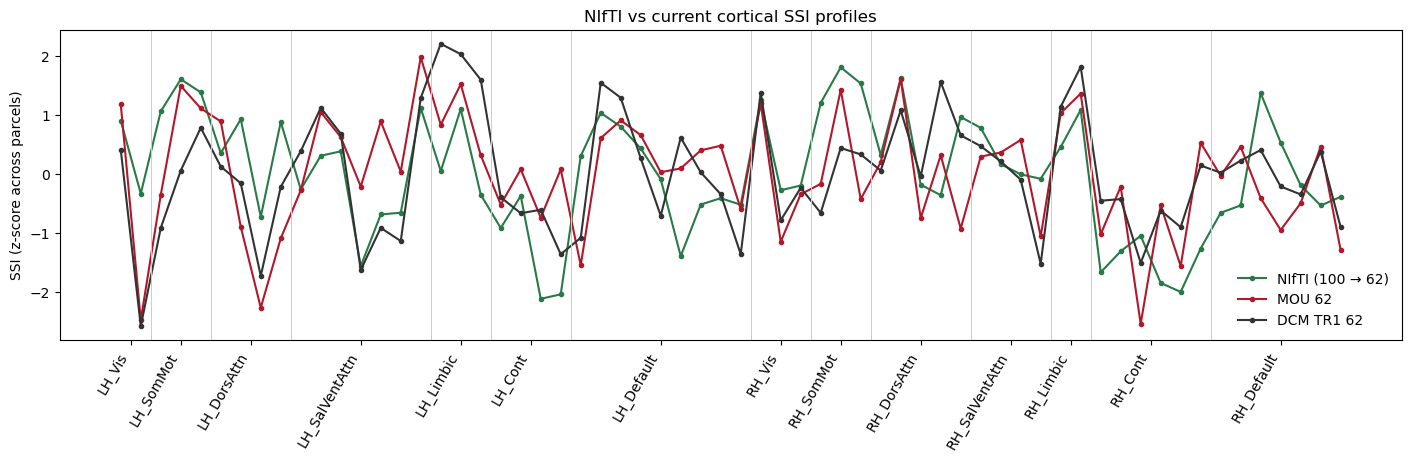

The NIfTI is not overwritten. Correlation measures similarity, not identity or provenance.


In [1]:
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import pearsonr, spearmanr, zscore

nii_project = Path('/home/benedetta/Scripts/Insight_project')
nii_path = nii_project / 'Notebook figure/nifti_S.nii'
nii_atlas_path = Path('/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii')
nii_img, nii_atlas = nib.load(nii_path), nib.load(nii_atlas_path)
assert nii_img.shape == nii_atlas.shape, 'Different voxel grids'
np.testing.assert_allclose(nii_img.affine, nii_atlas.affine, atol=1e-6)
nii_data = nii_img.get_fdata()
nii_labels = nii_atlas.get_fdata().astype(int)
assert np.isfinite(nii_data).all()
assert np.array_equal(np.unique(nii_labels), np.arange(101))
nii_profile100 = np.array([nii_data[nii_labels == k].mean() for k in range(1, 101)])
nii_spread100 = np.array([np.ptp(nii_data[nii_labels == k]) for k in range(1, 101)])
assert np.max(nii_spread100) < 1e-10, 'Map is not constant within Schaefer parcels'
nii_mapping = loadmat(nii_project / 'clust_idx_LEMON.mat')['clust_idx_LEMON'].ravel()[:100].astype(int)
nii_W = (nii_mapping[:, None] == np.arange(1, 63)).astype(float)
nii_W /= nii_W.sum(axis=0)
# Equal weight per original parcel, NOT voxel-weighted averaging.
nii_profile62 = nii_profile100 @ nii_W
nii_cache = nii_project / 'numpy files/SSI_cortical_DCM_MOU'
with np.load(nii_cache / 'MOU_all1013_RUN1_cortical62.npz') as z:
    nii_mou62 = z['SSI'].mean(axis=0)
with np.load(nii_cache / 'TR1_points16_62.npz') as z:
    nii_dcm62 = z['SSI_DCM_RUN1'].mean(axis=0)
with np.load(nii_cache / 'SSI_postaggregation_RUN1.npz') as z:
    nii_old100 = z['SSI100'].mean(axis=0)
    nii_old112 = z['SSI112'].mean(axis=0)[:100]
nii_comparisons = []
for label, extracted, reference in [
    ('MOU native62, N=1013', nii_profile62, nii_mou62),
    ('DCM TR1 cortical62, N=145', nii_profile62, nii_dcm62),
    ('MOU SSI100, N=144', nii_profile100, nii_old100),
    ('MOU SSI112 cortical entries, N=144', nii_profile100, nii_old112)]:
    slope, intercept = np.polyfit(reference, extracted, 1)
    nii_comparisons.append(dict(reference=label, parcels=len(reference),
        Pearson_r=pearsonr(extracted, reference)[0], Spearman_rho=spearmanr(extracted, reference)[0],
        RMSE=np.sqrt(np.mean((extracted-reference)**2)),
        same_values=np.allclose(extracted, reference, rtol=1e-5, atol=1e-8),
        scale=slope, offset=intercept))
nii_comparison_table = pd.DataFrame(nii_comparisons)
print('File:', nii_path)
print('Modification time (server):', datetime.fromtimestamp(nii_path.stat().st_mtime).isoformat())
print('Shape:', nii_img.shape, '| Unique cortical values:', len(np.unique(nii_data[nii_labels > 0])))
print('Maximum within-parcel range:', nii_spread100.max())
print('Nonzero background voxels:', np.count_nonzero(nii_data[nii_labels == 0]))
print(nii_comparison_table.to_string(index=False))
# Plot standardised profiles solely to compare spatial shapes across different scales.
nii_networks = pd.read_csv(nii_cache / 'cortical_networks.csv')
nii_net_order = [f'{h}_{net}' for h in ['LH','RH'] for net in ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']]
nii_groups = [(net, np.flatnonzero(nii_networks.network.to_numpy() == net)) for net in nii_net_order]
nii_groups = [(net, ix) for net, ix in nii_groups if len(ix)]
nii_order = np.concatenate([ix for _, ix in nii_groups])
nii_sizes = np.array([len(ix) for _, ix in nii_groups])
nii_centers = np.r_[0, np.cumsum(nii_sizes)[:-1]] + (nii_sizes-1)/2
fig_nii_check, ax_nii_check = plt.subplots(figsize=(14,4.5), constrained_layout=True)
for label, values, color in [('NIfTI (100 → 62)', nii_profile62, '#287a46'), ('MOU 62', nii_mou62, '#b2182b'), ('DCM TR1 62', nii_dcm62, '#333333')]:
    ax_nii_check.plot(zscore(values)[nii_order], '-o', ms=3, label=label, color=color)
for end in np.cumsum(nii_sizes)[:-1]: ax_nii_check.axvline(end-.5, color='.8', lw=.7)
ax_nii_check.set_xticks(nii_centers, [net for net, _ in nii_groups], rotation=60, ha='right')
ax_nii_check.set(ylabel='SSI (z-score across parcels)', title='NIfTI vs current cortical SSI profiles')
ax_nii_check.legend(frameon=False)
plt.show()
print('The NIfTI is not overwritten. Correlation measures similarity, not identity or provenance.')


## MOU SSI: mappa corticale Schaefer-100 con neuromaps

Media di gruppo dei profili **SSI100 salvati**, RUN1, 144 soggetti. D e S sono calcolate sulle sole 100 corticali; non è il vecchio NIfTI, né SSI112 tagliato dopo il calcolo. Superfici inflated fsLR 32k ottenute con `neuromaps.datasets.fetch_fslr`; assegnazione esatta tramite etichette CIFTI Schaefer-100 e rendering con Nilearn/Matplotlib. Nessuna soglia di significatività, scala simmetrica intorno a zero, valori positivi rossi e negativi blu; parete mediale esclusa. Resta l’assunzione sull’abbinamento degli ID MOU descritta sopra. La cella è autonoma e salva un solo JPG. [Neuromaps: fetch_fslr](https://netneurolab.github.io/neuromaps/generated/neuromaps.datasets.fetch_fslr.html).

/home/benedetta/Scripts/Insight_project/.deps/neuromaps/neuromaps/datasets/utils.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename
pixdim[1,2,3] should be non-zero; setting 0 dims to 1


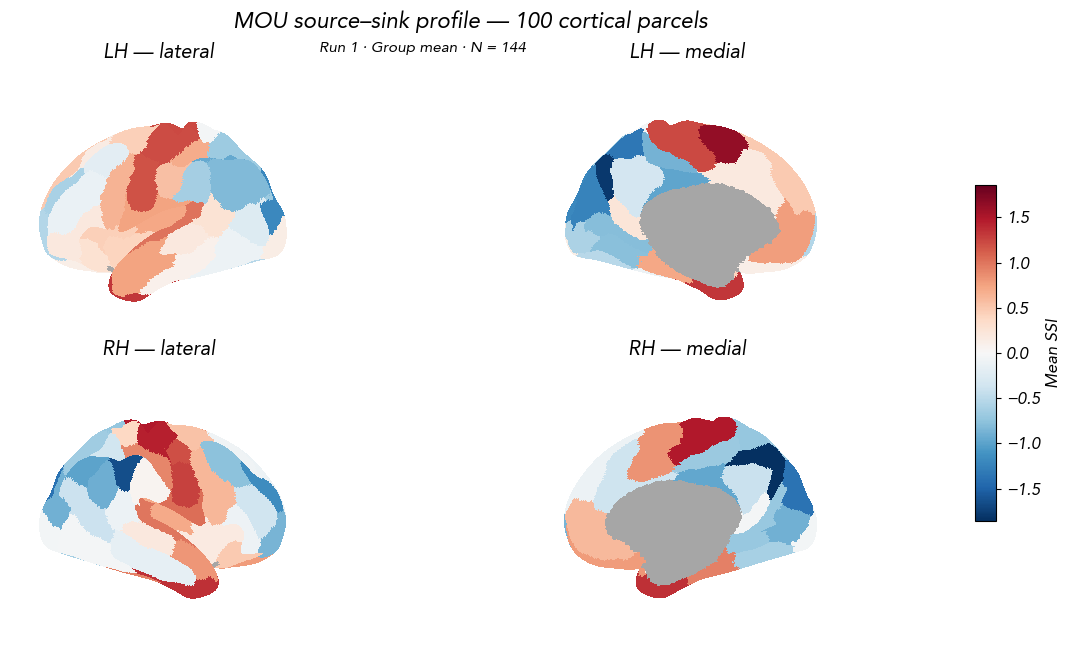

Saved: /home/benedetta/Scripts/Insight_project/Figures/SSI_cortical_DCM_MOU/MOU_SSI100_RUN1_surface.jpg
Source: SSI100, cortical-only product, N = 144
SSI range: -1.8579278572437674 1.6352208352426192


In [1]:
from pathlib import Path
import sys
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import font_manager, colors, cm
from nilearn import plotting

surface_project = Path('/home/benedetta/Scripts/Insight_project')
surface_deps = surface_project / '.deps/neuromaps'
if str(surface_deps) not in sys.path:
    sys.path.insert(0, str(surface_deps))
from neuromaps.datasets import fetch_fslr

# Saved subject-level SSI computed on cortical 100 x 100 J.T and Q0, RUN1.
# SSI100 differs from SSI112[:, :100], which includes subcortical contributions.
with np.load(surface_project / 'numpy files/SSI_cortical_DCM_MOU/SSI_postaggregation_RUN1.npz') as z:
    surface_subject_ids = z['subject_ids'].astype(str)
    surface_ssi_subjects = z['SSI100'].copy()
assert surface_ssi_subjects.shape == (len(surface_subject_ids), 100)
assert np.isfinite(surface_ssi_subjects).all()
surface_ssi100 = surface_ssi_subjects.mean(axis=0)

# Exact Schaefer label mapping in fsLR: no spatial interpolation of parcel values.
surface_cifti = nib.load(surface_project / 'Schaefer2018_100Parcels_7Networks_order.dlabel.nii')
surface_label_table = surface_cifti.header.get_axis(0).label[0]
surface_names = [line.split()[1] for line in
    Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt').read_text().splitlines() if line.strip()]
assert [surface_label_table[k][0] for k in range(1,101)] == surface_names
surface_labels = np.asarray(surface_cifti.dataobj)[0].astype(int)
assert np.array_equal(np.unique(surface_labels), np.arange(101))
surface_fslr = fetch_fslr(density='32k', data_dir=Path.home() / 'neuromaps-data', verbose=0)
surface_values = {}
for structure, sl, brain_model in surface_cifti.header.get_axis(1).iter_structures():
    hemi = 'left' if structure == 'CIFTI_STRUCTURE_CORTEX_LEFT' else 'right'
    values = np.full(brain_model.nvertices[structure], np.nan)
    parcel_labels = surface_labels[sl]
    valid = parcel_labels > 0
    values[brain_model.vertex[valid]] = surface_ssi100[parcel_labels[valid]-1]
    surface_values[hemi] = values
    for k in np.unique(parcel_labels[valid]):
        np.testing.assert_allclose(values[brain_model.vertex[parcel_labels == k]], surface_ssi100[k-1])

surface_limit = float(np.max(np.abs(surface_ssi100)))
surface_style = {'font.size':12}
surface_font = surface_project / 'Notebook figure/Avenir-Oblique.ttf'
if surface_font.exists():
    font_manager.fontManager.addfont(str(surface_font))
    surface_style['font.family'] = font_manager.FontProperties(fname=str(surface_font)).get_name()
with plt.rc_context(surface_style):
    surface_fig = plt.figure(figsize=(12,7), facecolor='white')
    surface_grid = surface_fig.add_gridspec(2,2,left=.02,right=.9,bottom=.05,top=.90,wspace=0,hspace=0)
    for row, hemi in enumerate(['left','right']):
        hi = 0 if hemi == 'left' else 1
        for col, view in enumerate(['lateral','medial']):
            ax = surface_fig.add_subplot(surface_grid[row,col], projection='3d')
            plotting.plot_surf_stat_map(
                str(surface_fslr['inflated'][hi]), surface_values[hemi],
                hemi=hemi, view=view, axes=ax, figure=surface_fig,
                cmap='RdBu_r', symmetric_cbar=True, vmin=-surface_limit, vmax=surface_limit,
                colorbar=False, avg_method='median', alpha=1,
                title=f'{"LH" if hi==0 else "RH"} — {view}')
    surface_cax = surface_fig.add_axes([.92,.25,.018,.48])
    surface_cb = surface_fig.colorbar(cm.ScalarMappable(norm=colors.Normalize(-surface_limit,surface_limit),cmap='RdBu_r'), cax=surface_cax)
    surface_cb.set_label('Mean SSI')
    surface_fig.suptitle('MOU source–sink profile — 100 cortical parcels', fontsize=16, y=.98)
    surface_fig.text(.46,.92,f'Run 1 · Group mean · N = {len(surface_subject_ids)}',ha='center',fontsize=11)
    surface_output = surface_project / 'Figures/SSI_cortical_DCM_MOU/MOU_SSI100_RUN1_surface.jpg'
    surface_output.parent.mkdir(parents=True,exist_ok=True)
    surface_fig.savefig(surface_output,dpi=300,bbox_inches='tight',facecolor='white')
    plt.show()
print('Saved:', surface_output)
print('Source: SSI100, cortical-only product, N =',len(surface_subject_ids))
print('SSI range:',surface_ssi100.min(),surface_ssi100.max())
